## Cosmic-web connectivity of Cluster129

Methods section *Connectivity* and Extended Data figure *Cosmic web around Cluster129*.

The connectivity $\kappa$ of a progenitor is the number of distinct cosmic-web filaments that reach it within a fixed
aperture. The filaments are extracted with DisPerSE from the dark-matter density field of each The Three Hundred zoom
(GIZMO-SIMBA 7k run), at the main progenitor of the 7k merger trees, at $z=4.038$ (snapshot 055) and $z=5.017$
(snapshot 047).

The notebook has three parts:

* **A. Numbers.** Every number of the Methods paragraph, recomputed from `data/connectivity_cluster129.hdf5`.
  This file holds the processed connectivity of all regions, the calibration counts of the persistence cut, the MDPL2
  parent-volume comparison and the Cluster129 skeletons.
* **B. Figure.** The Extended Data figure, from the same file.
* **C. Worked example.** The full method run on Cluster129 from the simulation data. It needs the snapshots on `/data20`
  and DisPerSE v0.9.25 (`mse`, `skelconv`). DisPerSE runs on one core and takes up to an hour per epoch.

The functions live in `connectivity.py`. The run over all 324 regions repeats part C for every zoom and every
persistence cut; it is not part of this repository.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from set_style import set_style
import connectivity as C

data = C.load_data('data/connectivity_cluster129.hdf5')

## A. Numbers

### Persistence cut

DisPerSE removes every pair of critical points whose values of $\delta$ differ by less than the persistence cut. We
use one absolute cut for all regions at a given epoch. The cut is calibrated by matching the density maxima to the
host haloes of the zooms, pooled over all regions. The hosts are the AHF haloes within $12\,h^{-1}$Mpc of the
progenitor with $M_{200c}\geq6\times10^{11}\,h^{-1}{\rm M_\odot}$ and at least 98 per cent of their mass in
high-resolution particles.

* **Purity** is the fraction of maxima whose nearest host lies within that host's $R_{200c}$.
* **Completeness** is the fraction of hosts whose nearest maximum lies within the host's $R_{200c}$.

We adopt the cut at which the two are closest to equal.

In [2]:
for z in (4, 5):
    c = data['calibration_7k'][f'z{z}']
    P, Cm = C.purity_completeness(c['n_pure'], c['n_cp'], c['n_comp'], c['n_anchor'])
    cut, Pa, Ca = C.adopted_cut(c['cuts'], c['n_pure'], c['n_cp'], c['n_comp'], c['n_anchor'])
    c3 = data['calibration_3k'][f'z{z}']
    cut3 = C.adopted_cut(c3['cuts'], c3['n_pure'], c3['n_cp'], c3['n_comp'], c3['n_anchor'])[0]
    print(f"z = {c['attrs']['redshift']:.3f}: {c['n_anchor'][0]} hosts in {c['attrs']['n_regions']} regions")
    print('   cut     ' + ' '.join(f'{x:6g}' for x in c['cuts']))
    print('   purity  ' + ' '.join(f'{x:6.2f}' for x in P))
    print('   complet.' + ' '.join(f'{x:6.2f}' for x in Cm))
    print(f'   adopted cut {cut:g} (purity {Pa:.2f}, completeness {Ca:.2f}); 3k run: cut {cut3:g}\n')

z = 4.038: 7580 hosts in 321 regions
   cut          1      2      3      4      5      6      8     12
   purity    0.22   0.35   0.48   0.60   0.69   0.76   0.84   0.91
   complet.  0.59   0.56   0.52   0.48   0.44   0.38   0.29   0.17
   adopted cut 3 (purity 0.48, completeness 0.52); 3k run: cut 3

z = 5.017: 2349 hosts in 316 regions
   cut          1      2      3      4      5      6      8     12
   purity    0.10   0.19   0.28   0.39   0.50   0.59   0.73   0.84
   complet.  0.65   0.62   0.59   0.56   0.50   0.44   0.33   0.17
   adopted cut 5 (purity 0.50, completeness 0.50); 3k run: cut 5



### Connectivity of the zoom progenitors

$\kappa$ is counted within a fixed comoving aperture of $1\,h^{-1}$Mpc. A halo-scaled aperture of $1.5\,R_{200c}$
cannot resolve a filament count for most progenitors: its median is about the smoothing scale $R_s=0.5\,h^{-1}$Mpc at
$z=4.038$ and below it at $z=5.017$. For Cluster129 the two apertures return the same $\kappa$.

In [3]:
v = C.paper_numbers(data)
print(f"median 1.5 R200c: {v['median_1p5R200_z4']:.2f} Mpc/h at z=4.038, {v['median_1p5R200_z5']:.2f} Mpc/h at z=5.017")
print(f"Cluster129: kappa(1 Mpc/h) = {v['k129_z4']:.0f}, kappa(1.5 R200c) = {v['k129_r200_z4']:.0f} at z=4.038; "
      f"{v['k129_z5']:.0f} and {v['k129_r200_z5']:.0f} at z=5.017")
print(f"{v['n_z4']} regions at z=4.038: Spearman rho(kappa, M200c) = {v['rho_z4']:.2f}, p = {10**v['logp_z4']:.0e}")
print(f"apertures 1-3 Mpc/h: rho = {v['ap_rho_min']:.2f}-{v['ap_rho_max']:.2f}, largest p = {v['ap_p_max']:.1e}")
print(f"z=4.038: progenitors with kappa >= {v['k129_z4']:.0f}: {v['n_at_least_z4']} (Cluster129 only)")
print(f"z=5.017: kappa = {v['k129_z5']:.0f} is exceeded by {v['n_higher_z5']} progenitors and shared by {v['n_tie_z5']} others")

median 1.5 R200c: 0.50 Mpc/h at z=4.038, 0.35 Mpc/h at z=5.017
Cluster129: kappa(1 Mpc/h) = 9, kappa(1.5 R200c) = 9 at z=4.038; 4 and 4 at z=5.017
321 regions at z=4.038: Spearman rho(kappa, M200c) = 0.37, p = 1e-11
apertures 1-3 Mpc/h: rho = 0.19-0.37, largest p = 4.7e-04
z=4.038: progenitors with kappa >= 9: 1 (Cluster129 only)
z=5.017: kappa = 4 is exceeded by 7 progenitors and shared by 49 others


### Haloes selected by their $z=4$ mass: the MDPL2 parent volume

The Three Hundred clusters are selected by their mass at $z=0$. To compare Cluster129 with haloes selected by their
mass at $z=4$, the same measurement was repeated in the MDPL2 parent volume at $z=4.038$, using the same pipeline,
persistence cut and aperture on $(30\,h^{-1}{\rm Mpc})^3$ cubes of the parent dark-matter particles.

* `top`: all Rockstar haloes with $M_{200c}\geq10^{13}\,h^{-1}{\rm M_\odot}$.
* `control`: haloes drawn at random between $10^{12}$ and $10^{13}\,h^{-1}{\rm M_\odot}$.
* `the300`: the zoom progenitors measured in the parent volume. The parent volume has the mass resolution of the
  3k run, so these are compared with the 3k zooms.

In [4]:
print(f"sample: {v['pk_n_top']} haloes >= 1e13 Msun/h and {v['pk_n_rand']} random haloes 1e12-1e13 Msun/h")
print(f"check against the 3k zooms: {v['pk_cal_n']} progenitors, mean |kappa_parent - kappa_zoom| = {v['pk_cal_absdiff']:.2f}; "
      f"Cluster129 kappa = {v['k129_zoom3k']:.0f} (3k zoom), {v['pk_k129_parent']:.0f} (parent volume)")
print(f"fit to the {v['pk_n_fit']} other haloes: kappa = {v['pk_slope']:.1f} log10(M200c) {v['pk_icpt']:+.1f} "
      f"(Spearman {v['pk_rho']:.2f}), scatter {v['pk_scatter']:.1f}")
print(f"Cluster129 lies {v['pk_excess']:.1f} filaments above the relation = {v['pk_excess_sig']:.1f} sigma; "
      f"{v['pk_n_other_ge']} other haloes above 1e13 Msun/h reach kappa >= {v['pk_k129_parent']:.0f}")

sample: 186 haloes >= 1e13 Msun/h and 300 random haloes 1e12-1e13 Msun/h
check against the 3k zooms: 316 progenitors, mean |kappa_parent - kappa_zoom| = 0.17; Cluster129 kappa = 8 (3k zoom), 7 (parent volume)
fit to the 485 other haloes: kappa = 1.7 log10(M200c) -18.3 (Spearman 0.55), scatter 1.1
Cluster129 lies 1.5 filaments above the relation = 1.4 sigma; 5 other haloes above 1e13 Msun/h reach kappa >= 7


## B. Extended Data figure

The figure shows the cosmic web around Cluster129 at $z=4.038$ (left) and $z=5.017$ (right).

* **Greyscale:** projected dark-matter density of a thin slab ($|\Delta z|<1.5\,h^{-1}$Mpc) through the node.
* **Red:** the DisPerSE filaments at the calibrated persistence cut.
* **Blue crosses:** the density maxima that survive the cut.
* **Circles:** tracer haloes of the MDPL2 parent volume, coloured by mass.
* **Star:** the node, with the $1.5\,R_{200c}$ aperture drawn as a dashed circle.

$\kappa$ counts filaments in three dimensions, so the slab shows only some of them.

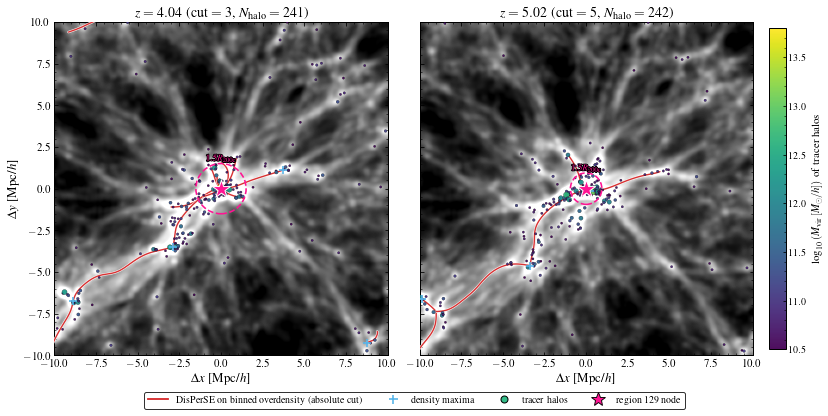

In [5]:
set_style('mnras')
fig = C.plot_web(data, out='plots/region129_griddisperse_web.png')
plt.show()

The greyscale can be recomputed from the snapshots on `/data20`, which takes about a minute per epoch:

In [6]:
for z in (4, 5):
    g = data['cluster129'][f'z{z}']
    img, zz, r200, cen = C.slab_image(g['attrs']['snapshot_file'], g['attrs']['ahf_file'])
    print(f"z = {zz:.3f}: same image as in the data file: {np.allclose(img, g['slab_image'], rtol=1e-6)}; "
          f"R200c = {r200:.3f} Mpc/h")

z = 4.038: same image as in the data file: True; R200c = 1.005 Mpc/h
z = 5.017: same image as in the data file: True; R200c = 0.629 Mpc/h


## C. Worked example: Cluster129 from the simulation data

These steps run the method on one zoom. For every region of the sample, the same steps were run at every persistence
cut, and the purity and completeness above come from those runs.

1. **Read the particles.** Take the high-resolution dark-matter particles in a $(30\,h^{-1}{\rm Mpc})^3$ cube centred
   on the main progenitor of the 7k merger tree.
2. **Build the density field.** Deposit the particles onto a $240^3$ grid by cloud-in-cell assignment, and express
   the field as the overdensity $\delta=\rho/\bar\rho_{\rm DM}-1$, with $\bar\rho_{\rm DM}$ the cosmic mean
   dark-matter density. Smooth it with a Gaussian of $R_s=0.5\,h^{-1}$Mpc.
3. **Run DisPerSE.** Use open boundaries and the absolute persistence cut: 3 at $z=4.038$, 5 at $z=5.017$. The
   Morse–Smale complex is computed once and then simplified at the cut.
4. **Post-process.** Remove arcs that end on the cube boundary or are shorter than $0.01\,h^{-1}$Mpc, join arcs that
   continue each other through a saddle point, and smooth the filaments.
5. **Count.** $\kappa$ is the number of filaments that cross a sphere of $1\,h^{-1}$Mpc (and of $1.5\,R_{200c}$)
   around the progenitor.

Set the environment variable `DISPERSE_BIN` (or edit the cell below) to the folder that holds `mse` and `skelconv`.

In [7]:
import os
DISPERSE_BIN = os.environ.get('DISPERSE_BIN', '/usr/local/bin')   # folder with mse and skelconv of DisPerSE v0.9.25
WORKDIR = 'disperse_work'
g = data['cluster129']['z4']
print(g['attrs']['snapshot_file'])
print(f"main progenitor at {np.round(g['centre'], 3)} Mpc/h, M200c = {g['M200c']:.3g} Msun/h, R200c = {g['R200c']:.3f} Mpc/h")

/data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_055.hdf5
main progenitor at [500.622 503.779 492.377] Mpc/h, M200c = 7.38e+13 Msun/h, R200c = 1.005 Mpc/h


In [8]:
# 1-2. particles in the cube and smoothed overdensity
pos, mdm = C.read_dm_cube(g['attrs']['snapshot_file'], g['centre'])
delta = C.density_field(pos, g['centre'], mdm)
print(f'{len(pos)} particles of {mdm:.3g} Msun/h; grid {delta.shape}, delta from {delta.min():.2f} to {delta.max():.0f}')

17251849 particles of 1.59e+08 Msun/h; grid (240, 240, 240), delta from -0.97 to 303


In [9]:
# 3-4. DisPerSE at the cut of z=4.038, then post-processing
skl = C.run_disperse(delta, f'{WORKDIR}/z4', g['cut'], DISPERSE_BIN)
arcs, end_types, maxima = C.parse_skeleton(skl)
filaments = C.postprocess(arcs, end_types)
print(f'{len(arcs)} arcs -> {len(filaments)} filaments; {len(maxima)} density maxima')

155 arcs -> 98 filaments; 67 density maxima


In [10]:
# 5. connectivity
print(f"kappa(1 Mpc/h) = {C.count_kappa(filaments, 1.0)}, kappa(1.5 R200c) = {C.count_kappa(filaments, 1.5 * g['R200c'])}")
stored = C.split_filaments(g['filament_pts'], g['filament_lens'])
same = len(stored) == len(filaments) and all(np.array_equal(a.astype(np.float32), b.astype(np.float32)) for a, b in zip(filaments, stored))
print('same filaments as in the data file:', same)

kappa(1 Mpc/h) = 9, kappa(1.5 R200c) = 9
same filaments as in the data file: True


At $z=5.017$, the same steps in one call:

In [11]:
g5 = data['cluster129']['z5']
r = C.measure_region(g5['attrs']['snapshot_file'], g5['centre'], g5['cut'], DISPERSE_BIN, f'{WORKDIR}/z5', r200c=g5['R200c'])
print(f"{len(r['filaments'])} filaments; kappa(1 Mpc/h) = {r['kappa_1Mpc']}, kappa(1.5 R200c) = {r['kappa_1p5R200']}")

26 filaments; kappa(1 Mpc/h) = 4, kappa(1.5 R200c) = 4
